
===== FIRST 5 ROWS =====
   blockchain  trust_score  data_integrity  transaction_time  fraud_incidents  \
0           0    44.030257       69.273253          4.092353                5   
1           1    56.096956       91.736987          3.953791                1   
2           1    75.877793       85.059986          3.266859                4   
3           1    89.134737       89.264036          5.698025                2   
4           0    55.376299       69.004687         16.571447                6   

   patient_satisfaction  stakeholders  
0              4.321855            69  
1              5.769232            90  
2              7.639082            37  
3              6.875269            62  
4              4.115032            22  

===== DATA INFO =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   blockchain 

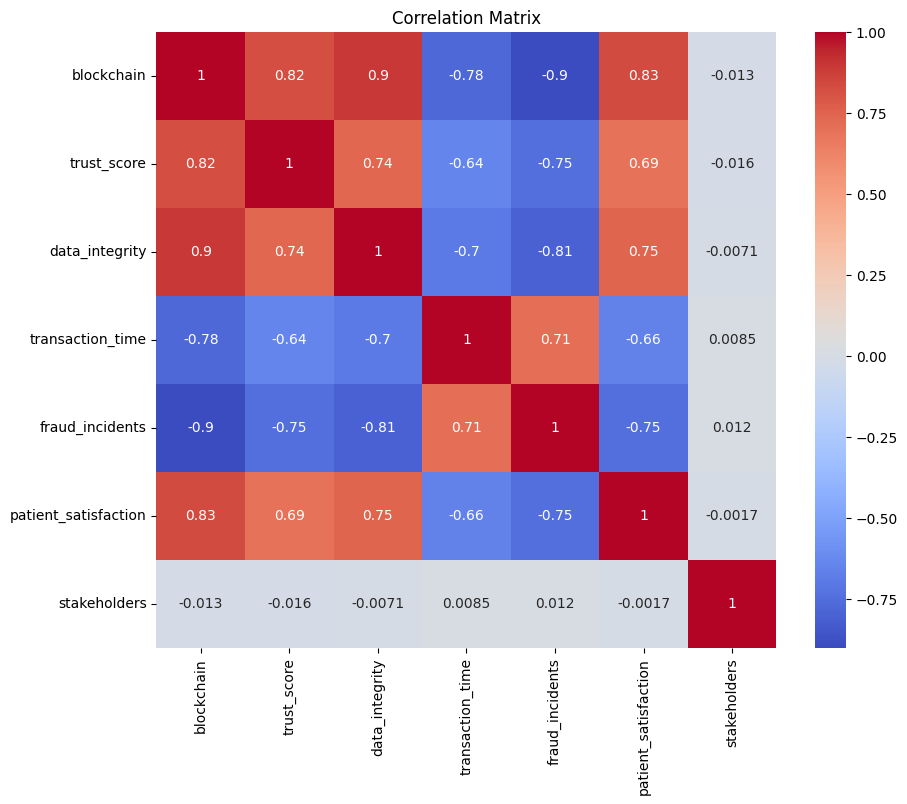

In [1]:
# =========================================================
# HEALTHCARE BLOCKCHAIN DATASET - COMPLETE PIPELINE
# =========================================================

# ======================
# 1. IMPORT LIBRARIES
# ======================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

import warnings
warnings.filterwarnings("ignore")

# ======================
# 2. LOAD DATA
# ======================
path = "/kaggle/input/healthcare-blockchain-dataset/healthcare_blockchain_dataset.csv"
df = pd.read_csv(path)

print("\n===== FIRST 5 ROWS =====")
print(df.head())

print("\n===== DATA INFO =====")
print(df.info())

print("\n===== DATA SHAPE =====")
print(df.shape)

print("\n===== MISSING VALUES =====")
print(df.isnull().sum())

# ======================
# 3. BASIC EDA
# ======================
print("\n===== STATISTICAL SUMMARY =====")
print(df.describe())

# Correlation Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

# ======================
# 4. PREPROCESSING
# ======================

# Drop duplicate rows
df = df.drop_duplicates()

# Fill missing values
df = df.fillna(df.mode().iloc[0])

# Encode categorical columns
le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

# ======================
# 5. DEFINE TARGET
# ======================

# 👉 IMPORTANT: Change this column name to your actual target column
target_column = df.columns[-1]   # Default: last column as target

X = df.drop(target_column, axis=1)
y = df[target_column]



Training size: (4000, 6)
Test size: (1000, 6)

===== CROSS-VALIDATION RESULTS =====

Logistic Regression
Accuracy: 0.9955 ± 0.0019
ROC-AUC : 0.9996 ± 0.0004

Random Forest
Accuracy: 0.9918 ± 0.0035
ROC-AUC : 0.9990 ± 0.0009

XGBoost
Accuracy: 0.9930 ± 0.0049
ROC-AUC : 0.9991 ± 0.0008

SVM
Accuracy: 0.9935 ± 0.0024
ROC-AUC : 0.9994 ± 0.0006

KNN
Accuracy: 0.9900 ± 0.0029
ROC-AUC : 0.9965 ± 0.0021

Gradient Boosting
Accuracy: 0.9902 ± 0.0052
ROC-AUC : 0.9992 ± 0.0006

===== FINAL TEST SET EVALUATION =====

--------------------------------------
Model: Logistic Regression
--------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0     0.9822    0.9920    0.9871       500
           1     0.9919    0.9820    0.9869       500

    accuracy                         0.9870      1000
   macro avg     0.9870    0.9870    0.9870      1000
weighted avg     0.9870    0.9870    0.9870      1000

Test ROC-AUC: 0.9997


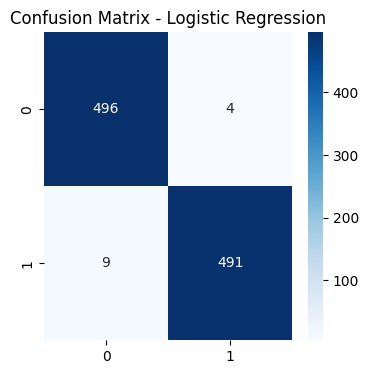

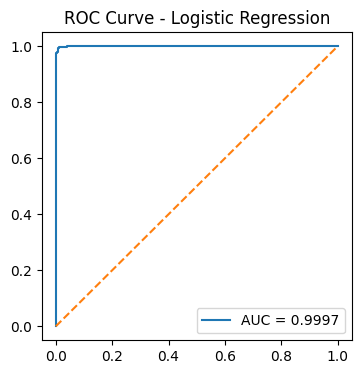


--------------------------------------
Model: Random Forest
--------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0     0.9881    0.9940    0.9910       500
           1     0.9940    0.9880    0.9910       500

    accuracy                         0.9910      1000
   macro avg     0.9910    0.9910    0.9910      1000
weighted avg     0.9910    0.9910    0.9910      1000

Test ROC-AUC: 0.9997


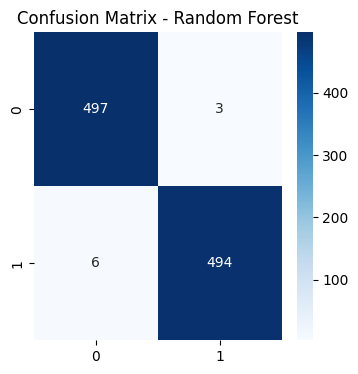

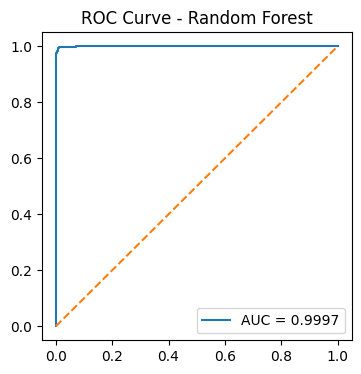


--------------------------------------
Model: XGBoost
--------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0     0.9803    0.9940    0.9871       500
           1     0.9939    0.9800    0.9869       500

    accuracy                         0.9870      1000
   macro avg     0.9871    0.9870    0.9870      1000
weighted avg     0.9871    0.9870    0.9870      1000

Test ROC-AUC: 0.9995


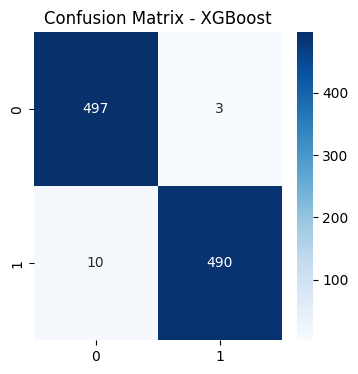

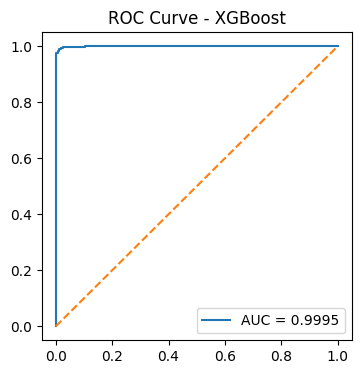


--------------------------------------
Model: SVM
--------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0     0.9841    0.9880    0.9860       500
           1     0.9880    0.9840    0.9860       500

    accuracy                         0.9860      1000
   macro avg     0.9860    0.9860    0.9860      1000
weighted avg     0.9860    0.9860    0.9860      1000

Test ROC-AUC: 0.9995


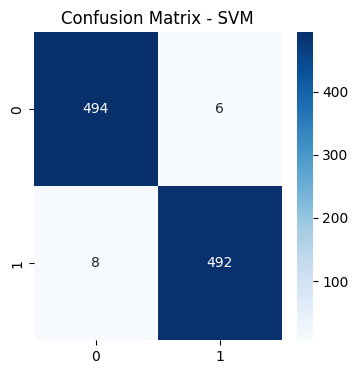

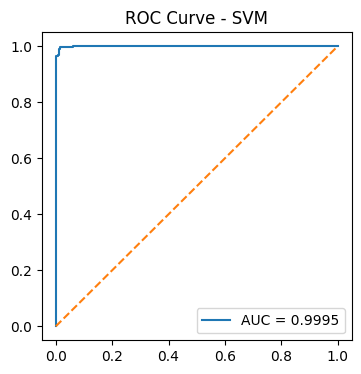


--------------------------------------
Model: KNN
--------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0     0.9841    0.9900    0.9870       500
           1     0.9899    0.9840    0.9870       500

    accuracy                         0.9870      1000
   macro avg     0.9870    0.9870    0.9870      1000
weighted avg     0.9870    0.9870    0.9870      1000

Test ROC-AUC: 0.9936


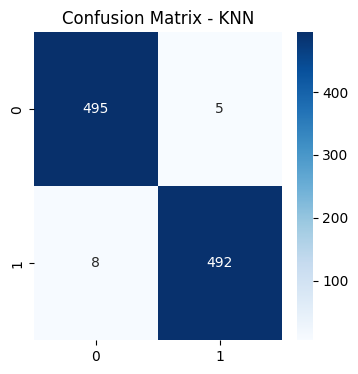

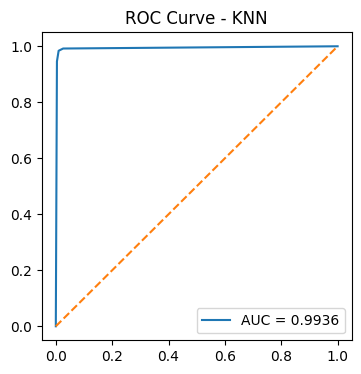


--------------------------------------
Model: Gradient Boosting
--------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0     0.9842    0.9960    0.9901       500
           1     0.9960    0.9840    0.9899       500

    accuracy                         0.9900      1000
   macro avg     0.9901    0.9900    0.9900      1000
weighted avg     0.9901    0.9900    0.9900      1000

Test ROC-AUC: 0.9995


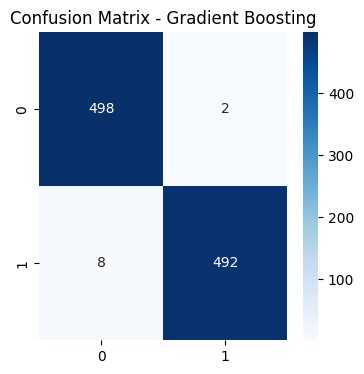

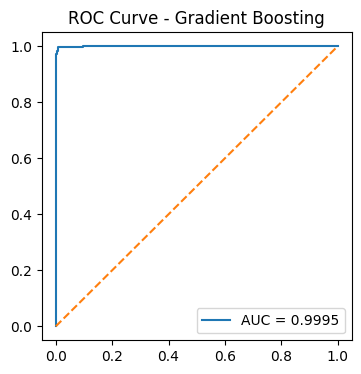


===== FINAL MODEL RANKING =====
                 Model  Test ROC-AUC
0  Logistic Regression      0.999700
1        Random Forest      0.999652
5    Gradient Boosting      0.999520
3                  SVM      0.999460
2              XGBoost      0.999456
4                  KNN      0.993594

Noisy Realistic Pipeline Completed Successfully ✅


In [22]:
# =========================================================
# HEALTHCARE BLOCKCHAIN - NOISY & REALISTIC VERSION
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# =========================================================
# 1. LOAD DATA
# =========================================================

path = "/kaggle/input/healthcare-blockchain-dataset/healthcare_blockchain_dataset.csv"
df = pd.read_csv(path)

df['transaction_time'] = df['transaction_time'].abs()
df = df.drop_duplicates()

# =========================================================
# 2. DEFINE FEATURES & TARGET
# =========================================================

X = df.drop("blockchain", axis=1)
y = df["blockchain"]

# =========================================================
# 3. ADD GAUSSIAN NOISE (MAKE PROBLEM REALISTIC)
# =========================================================

np.random.seed(42)
noise_strength = 3   # you can increase to 3 or 4 if still too easy

X_noisy = X.copy()
X_noisy += np.random.normal(0, noise_strength, X.shape)

# =========================================================
# 4. TRAIN / TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X_noisy, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training size:", X_train.shape)
print("Test size:", X_test.shape)

# =========================================================
# 5. DEFINE MODELS (LEAKAGE SAFE)
# =========================================================

models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=300))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=3))
    ]),

    "Gradient Boosting": GradientBoostingClassifier()
}

# =========================================================
# 6. CROSS-VALIDATION (TRAIN DATA ONLY)
# =========================================================

print("\n===== CROSS-VALIDATION RESULTS =====")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models.items():

    acc_scores = cross_val_score(model, X_train, y_train,
                                 cv=skf, scoring="accuracy")

    auc_scores = cross_val_score(model, X_train, y_train,
                                 cv=skf, scoring="roc_auc")

    print(f"\n{name}")
    print("Accuracy: %.4f ± %.4f" % (acc_scores.mean(), acc_scores.std()))
    print("ROC-AUC : %.4f ± %.4f" % (auc_scores.mean(), auc_scores.std()))

    cv_results.append([name, acc_scores.mean(), auc_scores.mean()])

# =========================================================
# 7. FINAL TEST EVALUATION
# =========================================================

print("\n===== FINAL TEST SET EVALUATION =====")

final_results = []

for name, model in models.items():

    print("\n--------------------------------------")
    print(f"Model: {name}")
    print("--------------------------------------")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, digits=4))

    print("Test ROC-AUC:", round(auc, 4))

    final_results.append([name, auc])

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.figure(figsize=(4,4))
    plt.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    plt.plot([0,1],[0,1],'--')
    plt.title(f"ROC Curve - {name}")
    plt.legend()
    plt.show()

# =========================================================
# 8. FINAL MODEL RANKING
# =========================================================

final_df = pd.DataFrame(final_results,
                        columns=["Model", "Test ROC-AUC"])

print("\n===== FINAL MODEL RANKING =====")
print(final_df.sort_values(by="Test ROC-AUC", ascending=False))

print("\nNoisy Realistic Pipeline Completed Successfully ✅")

In [26]:
import shap
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("/kaggle/working/shap_outputs", exist_ok=True)

X_sample = X_train.iloc[:200]

feature_importance_comparison = {}

for name, model in models.items():

    print("\n=====================================")
    print(f"SHAP Analysis for Model: {name}")
    print("=====================================")

    # Use predict_proba for ALL models (stable approach)
    explainer = shap.Explainer(model.predict_proba, X_sample)
    shap_values = explainer(X_sample)

    values = shap_values.values

    # Binary classification → take class 1
    if values.ndim == 3:
        shap_vals = values[:, :, 1]
        base_value = shap_values.base_values[:, 1].mean()
    else:
        shap_vals = values
        base_value = shap_values.base_values.mean()

    # ===============================
    # GLOBAL SUMMARY
    # ===============================
    shap.summary_plot(shap_vals, X_sample, show=False)
    plt.title(f"SHAP Summary - {name}")
    plt.savefig(f"/kaggle/working/shap_outputs/{name}_summary.png",
                bbox_inches='tight')
    plt.close()

    # ===============================
    # GLOBAL BAR
    # ===============================
    shap.summary_plot(shap_vals, X_sample, plot_type="bar", show=False)
    plt.title(f"SHAP Bar - {name}")
    plt.savefig(f"/kaggle/working/shap_outputs/{name}_bar.png",
                bbox_inches='tight')
    plt.close()

    # ===============================
    # LOCAL WATERFALL
    # ===============================
    shap.plots._waterfall.waterfall_legacy(
        base_value,
        shap_vals[0],
        feature_names=X.columns,
        show=False
    )

    plt.title(f"SHAP Waterfall - {name}")
    plt.savefig(f"/kaggle/working/shap_outputs/{name}_waterfall.png",
                bbox_inches='tight')
    plt.close()

    feature_importance_comparison[name] = np.abs(shap_vals).mean(axis=0)

comparison_df = pd.DataFrame(feature_importance_comparison,
                             index=X.columns)

comparison_df.to_csv("/kaggle/working/shap_feature_comparison.csv")

print("\nSHAP Analysis Completed Successfully ✅")


SHAP Analysis for Model: Logistic Regression

SHAP Analysis for Model: Random Forest


ExactExplainer explainer: 201it [00:17,  4.89it/s]                         



SHAP Analysis for Model: XGBoost

SHAP Analysis for Model: SVM


ExactExplainer explainer: 201it [00:11,  2.19it/s]                         



SHAP Analysis for Model: KNN


ExactExplainer explainer: 201it [00:19,  4.98it/s]                         



SHAP Analysis for Model: Gradient Boosting

SHAP Analysis Completed Successfully ✅


XGBoost_summary.png


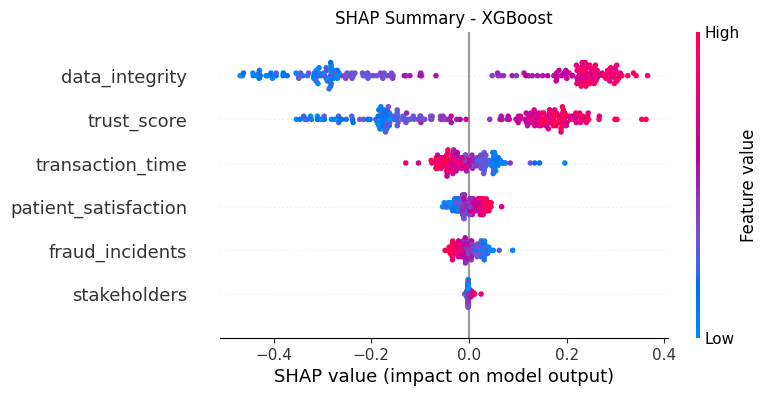

Gradient Boosting_waterfall.png


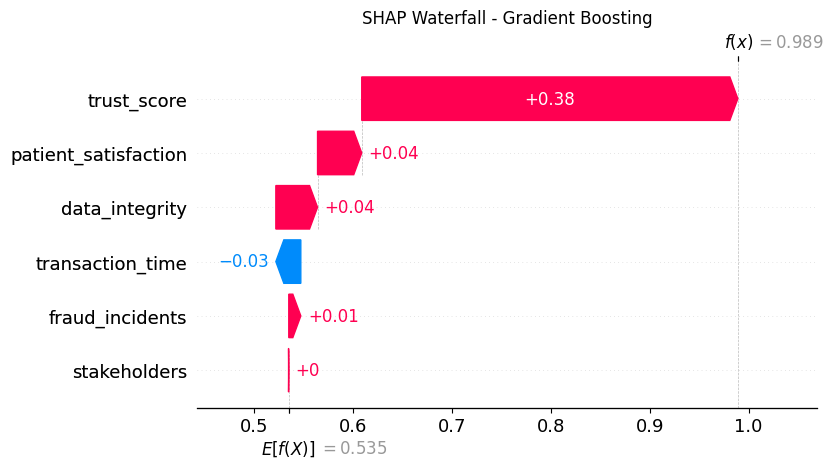

KNN_bar.png


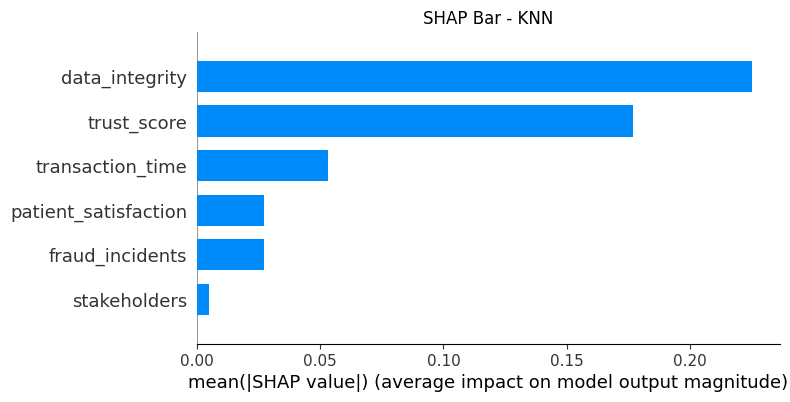

Random Forest_bar.png


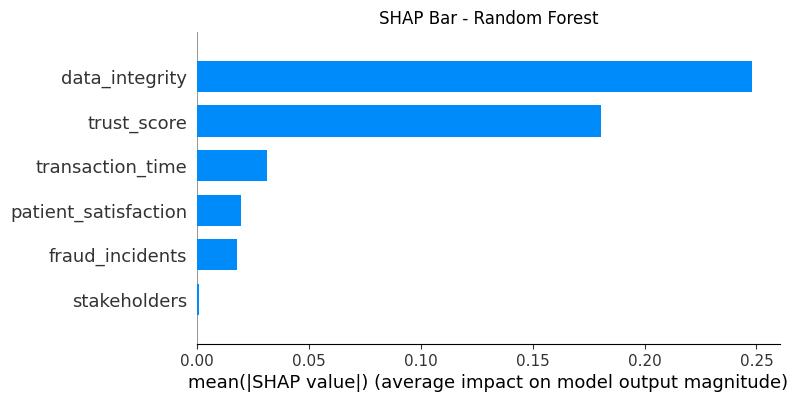

Gradient Boosting_summary.png


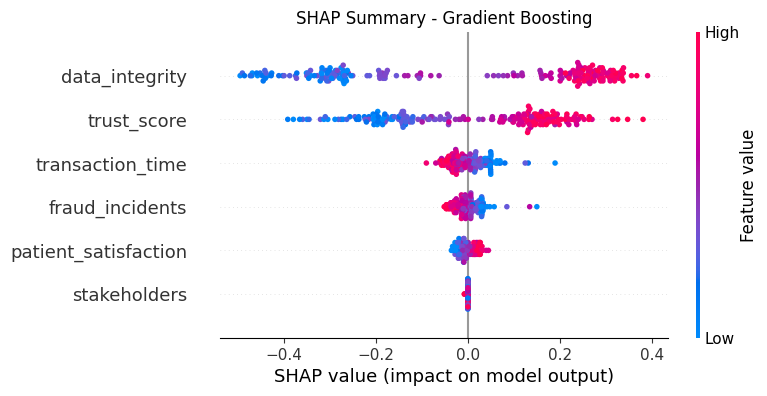

XGBoost_bar.png


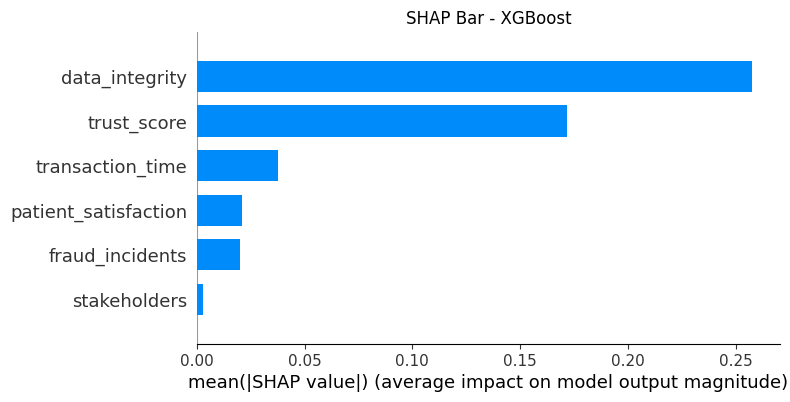

SVM_summary.png


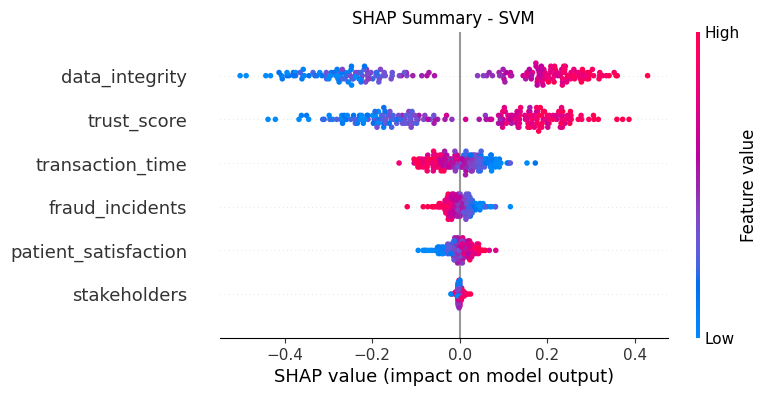

Logistic Regression_summary.png


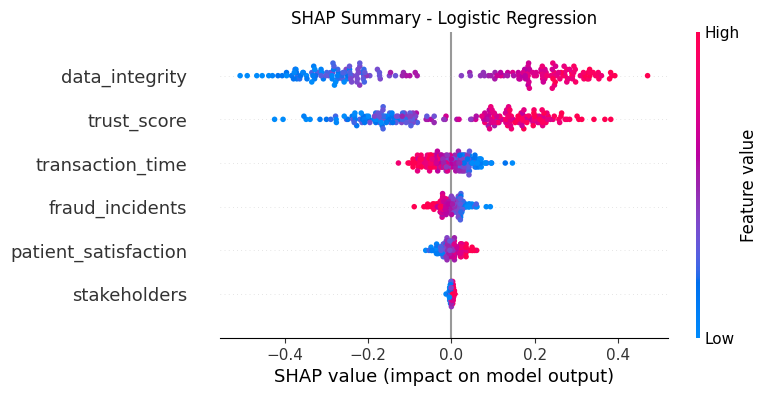

SVM_waterfall.png


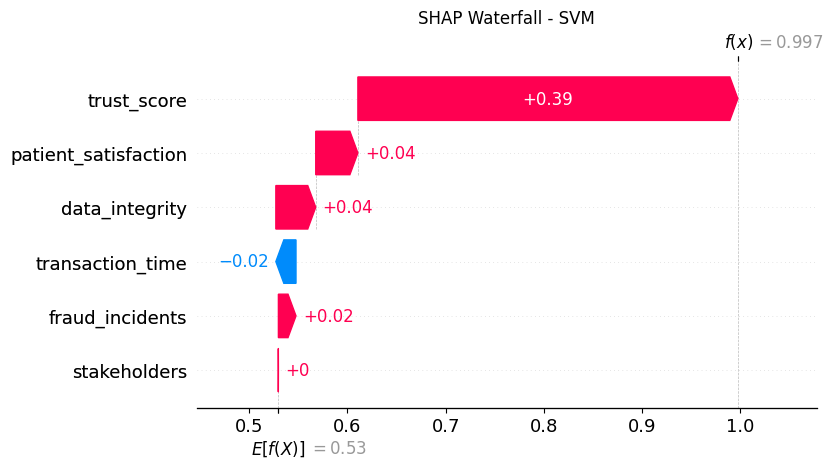

SVM_bar.png


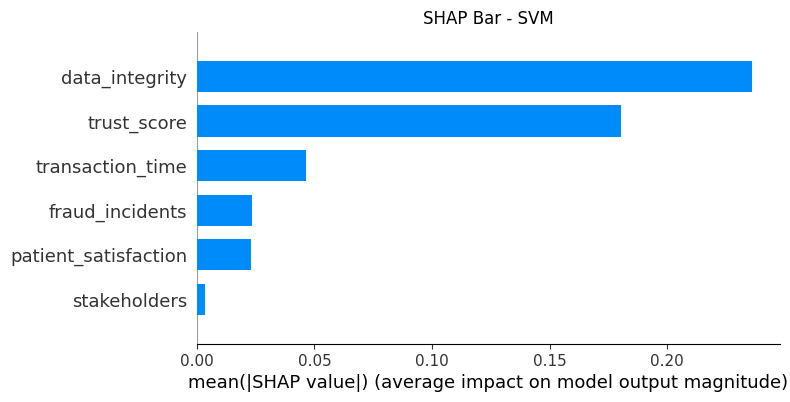

KNN_waterfall.png


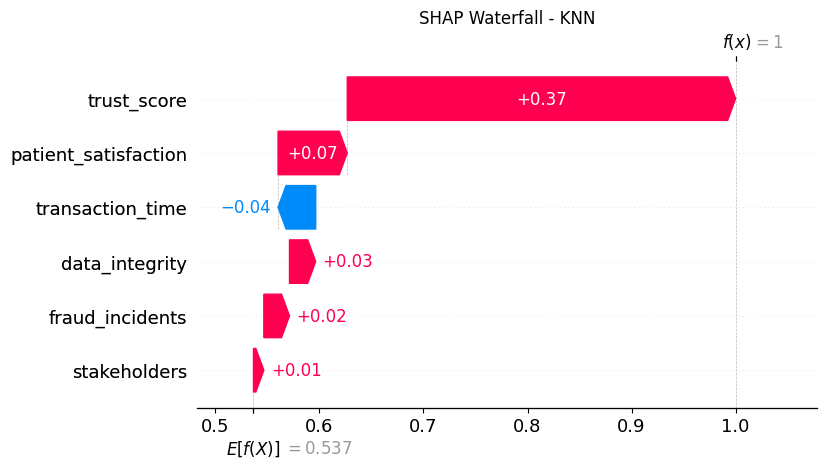

XGBoost_waterfall.png


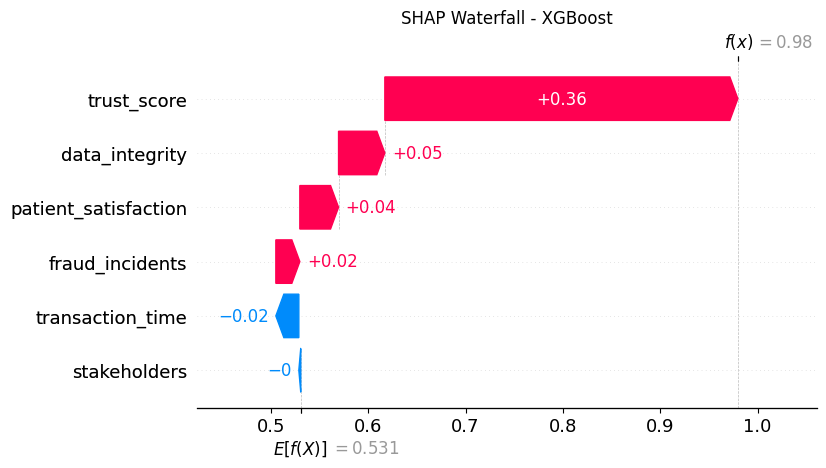

KNN_summary.png


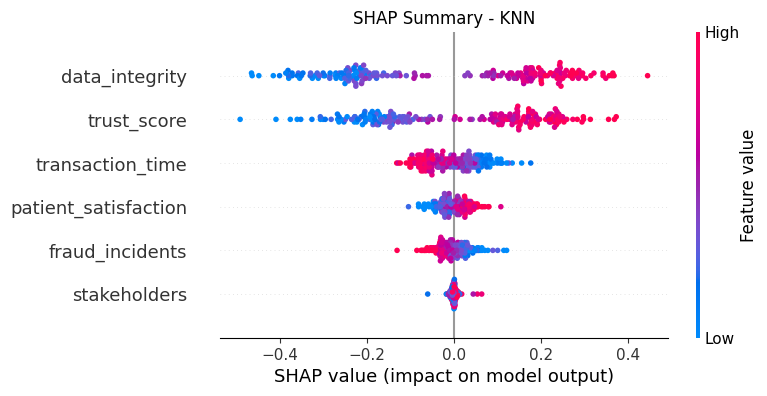

Random Forest_waterfall.png


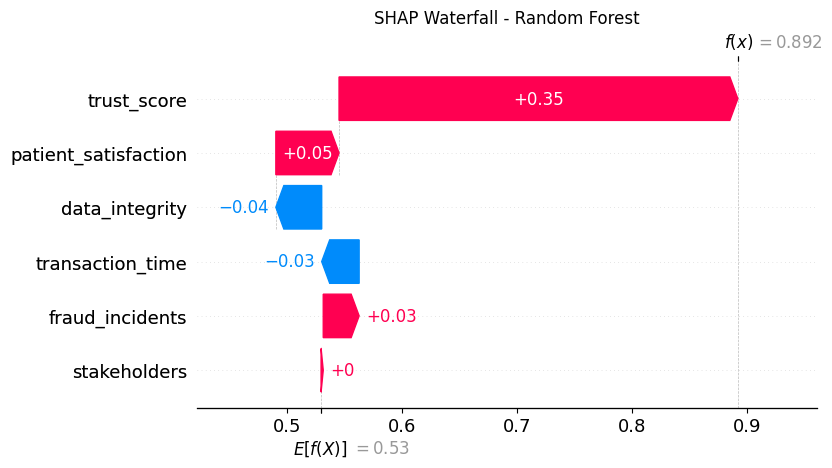

Random Forest_summary.png


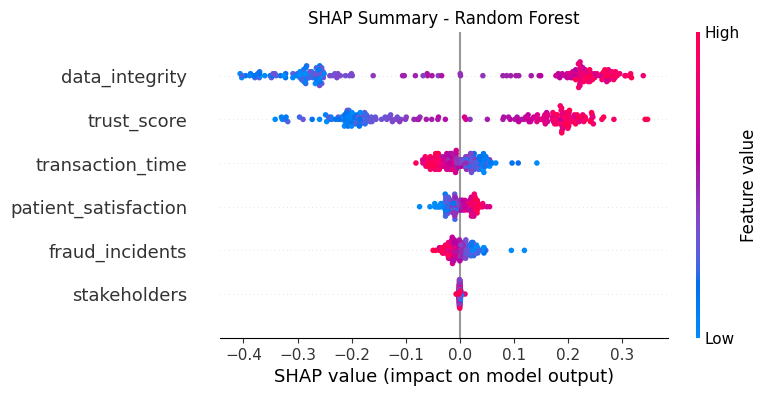

Gradient Boosting_bar.png


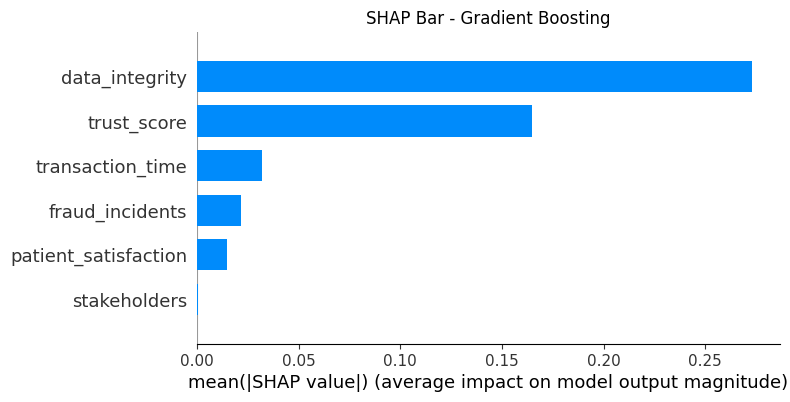

Logistic Regression_bar.png


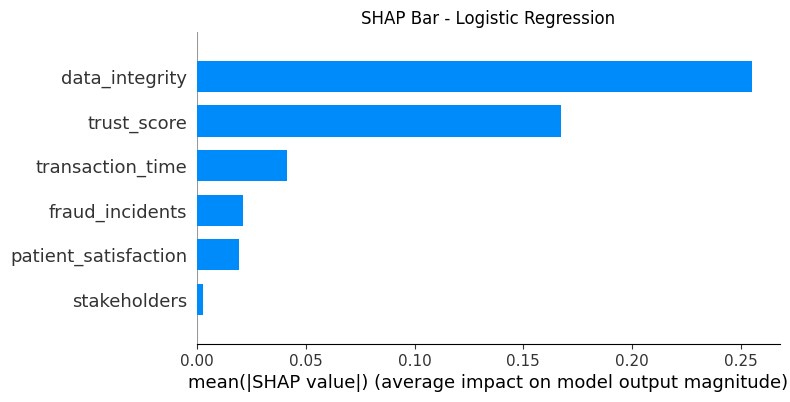

Logistic Regression_waterfall.png


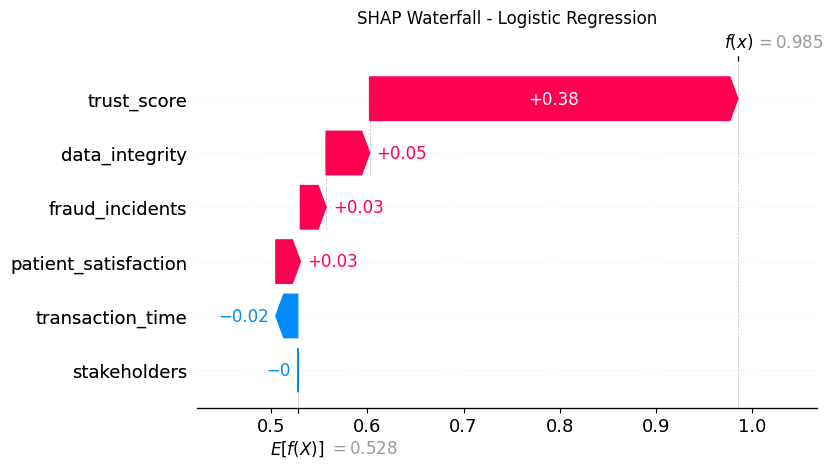

In [28]:
import os
from IPython.display import Image, display

folder = "/kaggle/working/shap_outputs"

for file in os.listdir(folder):
    if file.endswith(".png"):
        print(file)
        display(Image(filename=os.path.join(folder, file)))